<a href="https://colab.research.google.com/github/soyun-p/0228_git/blob/master/Week4_2_KNN(1)_Iris.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 4-2: K-Nearest Neighbors (Practice)
**Date:** 2025-09-24  
**Instructor:** Hong-Kyun Bae, Kookmin University

---

## Contents

1. **KNN with Iris Dataset**
   - 데이터 다운로드
   - 훈련/테스트 데이터셋 구분
   - KNN 구현
   - N-fold Cross validation (N겹 교차 검증)
   - K 값 변화에 따른 정확도 그래프

2. **KNN with MovieLens 100K Dataset**
   - 데이터 다운로드
   - 유저-아이템 행렬 생성
   - 유저 간 유사도 계산 (Cosine Similarity)
   - KNN 구현

### 1. KNN with Iris Dataset

In [ ]:
# =============================
# 0. 라이브러리 불러오기
# =============================

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# =============================
# 1-1. 데이터 다운로드

# wget: url로부터 파일을 다운로드 받는 쉘 명령어
# unzip: zip 압축 파일을 해제하는 쉘 명령어
# =============================

!wget https://archive.ics.uci.edu/static/public/53/iris.zip
!unzip iris.zip

![Iris Flower](https://miro.medium.com/v2/resize:fit:720/format:webp/1*kXYKlCF_wBBm9rIuAlz5Yw.png)

In [ ]:
!ls

bezdekIris.data  iris.data   iris.zip	 sample_data
Index		 iris.names  iris.zip.1


In [ ]:
!find /content -name "iris.data"

/content/iris.data


In [ ]:
# =============================
# 1-2. 데이터 불러오기

# X (특징): sepal length, sepal width, petal length, petal width
# Y (레이블): 0 (setosa), 1 (versicolor), 2 (virginica)
# =============================

X = []
Y = []
for line in open("/content/iris.data", "r"):
  line = line.strip()
  if line != "":
    tokens = line.split(',')
    X.append([float(t) for t in tokens[:4]])
    Y.append(tokens[4])

In [ ]:
X

In [ ]:
Y

In [ ]:
labels = list(set(Y))
Y = [labels.index(a) for a in Y]

In [ ]:
Y

In [ ]:
X = np.array(X)
Y = np.array(Y)

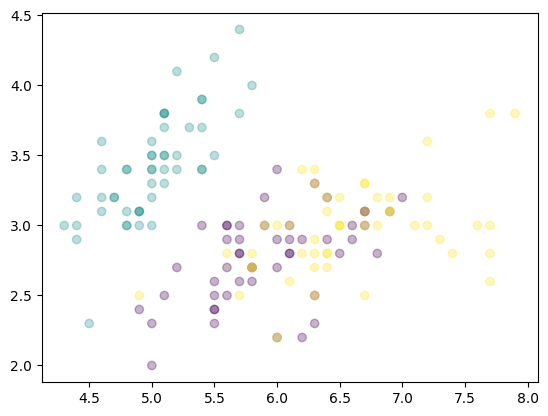

In [ ]:
# =============================
# 1-3. 데이터 살펴보기

# plt.scatter: 각 데이터 샘플을 점으로 표시
# X[:,0]: X 행렬의 첫 번째 열 (sepal length)
# X[:,1]: X 행렬의 두 번째 열 (sepal width)
# c=Y: 점의 색깔을 Y의 레이블에 따라 다르게 표시
# alpha: 점의 투명도 (0: 투명, 1: 불투명)
# =============================

import matplotlib.pyplot as plt

plt.scatter(X[:,0], X[:,1], c=Y, alpha=0.3)
plt.show()

In [ ]:
# =============================
# 2. 훈련/테스트 데이터셋 구분
# =============================

perm = np.random.permutation(len(X))

n_trains = int(len(X) * 0.8)

X_train = X[perm[:n_trains]]
Y_train = Y[perm[:n_trains]]
X_test = X[perm[n_trains:]]
Y_test = Y[perm[n_trains:]]

In [ ]:
# =============================
# 3-1. KNN 구현

# np.linalg.norm: norm (기본형: L2-norm 즉, 유클리드 거리) 계산
# np.argsort: 배열을 정렬했을 때의 인덱스 순서 반환
# np.bincount: 배열 원소별 등장 횟수 카운트
# =============================

K = 5
queries = X_test

predictions = []

for q in queries:
  dists = np.linalg.norm(X_train-q, axis=1)
  # Ex) X_train[0] = [5.1, 3.5, 1.4, 0.2], q = [4.9, 3.0, 1.4, 0.2]
  #     --> X_train[0]-q = [0.2, 0.5, 0.0, 0.0]
  #     --> Euclid distance = np.sqrt(0.2**2 + 0.5**2 + 0**2 + 0**2)

  knns = np.argsort(dists)[:K]
  counts = np.bincount(Y_train[knns])

  predictions.append(np.argmax(counts))

In [ ]:
# =============================
# 3-1. KNN 구현 (클래스로 표현)
# =============================

class KNNClassifier:
  def __init__(self, K):
    self.K = K

  def fit(self, X, Y):
    self.X = X
    self.Y = Y

  def predict(self, queries):
    predictions = []
    for q in queries:
      dists = np.linalg.norm(self.X-q, axis=1)
      knns = np.argsort(dists)[:self.K]
      counts = np.bincount(self.Y[knns])
      predictions.append(np.argmax(counts))

    return np.array(predictions)

In [ ]:
# =============================
# 3-2. KNN 분류기 정확도 평가
# =============================

knn = KNNClassifier(5)
knn.fit(X_train, Y_train)

test_pred = knn.predict(X_test)

print("Accuracy:", (test_pred == Y_test).mean())

Accuracy: 0.9666666666666667


In [ ]:
# =============================
# 4-1. N-CV 수행 함수 정의
# =============================

def CV_score(knn, X, Y, cv):
  n = len(X)
  perm = np.random.permutation(n)
  X = X[perm]
  Y = Y[perm]
  scores = []

  for i in range(cv):
    start = i*n // cv
    end = (i+1)*n // cv
    X_test = X[start:end]
    Y_test = Y[start:end]
    X_train = np.concatenate([X[:start], X[end:]])
    Y_train = np.concatenate([Y[:start], Y[end:]])

    knn.fit(X_train, Y_train)
    pred = knn.predict(X_test)
    scores.append((pred == Y_test).mean())

  return np.array(scores)

In [ ]:
# =============================
# 4-2. N-CV를 통한 정확도 평가
# =============================

knn = KNNClassifier(5)
scores = CV_score(knn, X, Y, 5)

print("Accuracy:", scores.mean())

Accuracy: 0.9666666666666666


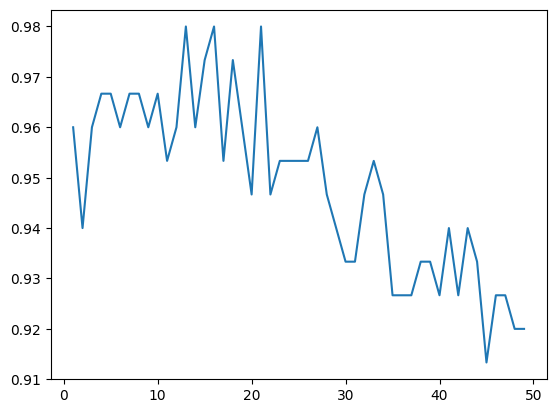

In [ ]:
# =============================
# 5. K 값 변화에 따른 정확도 관찰
# =============================

scores = []

for K in range(1, 50):
  knn = KNNClassifier(K)
  score = CV_score(knn, X, Y, 5).mean()
  scores.append(score)

plt.plot(range(1,50), scores)
plt.show()

In [ ]:
# =============================
# 참고: Scikit-learn을 이용한 KNN 분류기 구현
# =============================

import numpy as np

from sklearn.datasets import load_iris
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

iris = load_iris()
X = iris.data
Y = iris.target
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, Y_train)

Y_test_pred = knn.predict(X_test)

print("Accuracy:", accuracy_score(Y_test_pred, Y_test))

Accuracy: 0.9666666666666667
